In [27]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [28]:
# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [29]:
# ==========================================
# 1. DATA LOADING & AUDIT
# ==========================================

# Path to the locally downloaded dataset
file_path = "yellow_tripdata_2023-01.parquet"

print("Loading NYC TLC Parquet data from local file...")

# Load the locally downloaded dataset
raw_df = pd.read_parquet(file_path)

# Randomly sample 100,000 records for computational efficiency
raw_df = raw_df.sample(
    n=100000,
    random_state=RANDOM_STATE
)

print("--- Raw Dataset Audit ---")

# Dataset shape
print(f"\nDataset Shape: {raw_df.shape}")

# Dataset information
print("\nDataset Information:")
raw_df.info()

# Data types
print("\nData Types:")
print(raw_df.dtypes)

# Missing values
print("\nMissing Values Count:")
print(raw_df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows Count:")
print(raw_df.duplicated().sum())

# Target distribution
print("\nTarget (Fare Amount) Distribution:")
print(raw_df["fare_amount"].describe())

print("\nFare Amount Value Counts (Top 10):")
print(raw_df["fare_amount"].value_counts().head(10))

Loading NYC TLC Parquet data from local file...
--- Raw Dataset Audit ---

Dataset Shape: (100000, 19)

Dataset Information:
<class 'pandas.DataFrame'>
Index: 100000 entries, 2790731 to 13812
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               100000 non-null  int64         
 1   tpep_pickup_datetime   100000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  100000 non-null  datetime64[us]
 3   passenger_count        97714 non-null   float64       
 4   trip_distance          100000 non-null  float64       
 5   RatecodeID             97714 non-null   float64       
 6   store_and_fwd_flag     97714 non-null   str           
 7   PULocationID           100000 non-null  int64         
 8   DOLocationID           100000 non-null  int64         
 9   payment_type           100000 non-null  int64         
 10  fare_amount            100000 non-null  float64   

In [30]:
print("\n--- First 5 Rows of the Dataset ---")
raw_df.head()


--- First 5 Rows of the Dataset ---


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
2790731,2,2023-01-29 17:52:02,2023-01-29 17:56:43,1.0,1.17,1.0,N,262,74,2,7.2,0.0,0.5,0.00,0.0,1.0,11.20,2.5,0.0
666153,1,2023-01-08 15:57:24,2023-01-08 16:02:47,1.0,0.90,1.0,N,229,237,2,6.5,2.5,0.5,0.00,0.0,1.0,10.50,2.5,0.0
1985683,2,2023-01-21 19:38:01,2023-01-21 19:45:02,1.0,0.95,1.0,N,45,261,1,7.9,0.0,0.5,2.38,0.0,1.0,14.28,2.5,0.0
2154231,2,2023-01-23 16:07:31,2023-01-23 16:26:46,5.0,0.88,1.0,N,237,141,1,16.3,2.5,0.5,1.50,0.0,1.0,24.30,2.5,0.0
2493619,2,2023-01-26 21:21:08,2023-01-26 21:24:48,2.0,1.03,1.0,N,229,140,1,6.5,1.0,0.5,2.30,0.0,1.0,13.80,2.5,0.0


In [31]:
# ==========================================
# 2. DATA CLEANING
# ==========================================

df = raw_df.copy()

# Datetime Parsing & Duration
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

df['trip_duration_min'] = (
    (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime'])
    .dt.total_seconds() / 60.0
)

# Check and remove duplicate rows
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

# Outlier and invalid-value filtering
# Thresholds are chosen to remove clearly unrealistic records
# while retaining valid taxi trips.
df = df[
    (df['trip_distance'] > 0.1) & (df['trip_distance'] < 100) &
    (df['fare_amount'] > 2.5) & (df['fare_amount'] < 300) &
    (df['trip_duration_min'] > 1.0) & (df['trip_duration_min'] < 180) &
    (df['passenger_count'] > 0) & (df['passenger_count'] <= 6)
].copy()

# Fill missing numerical values using the median
df['congestion_surcharge'] = df['congestion_surcharge'].fillna(
    df['congestion_surcharge'].median()
)

df['airport_fee'] = df['airport_fee'].fillna(
    df['airport_fee'].median()
)

# Fill missing categorical values using the most frequent category
df['RatecodeID'] = df['RatecodeID'].fillna(
    df['RatecodeID'].mode()[0]
).astype(str)

df['store_and_fwd_flag'] = df['store_and_fwd_flag'].fillna(
    df['store_and_fwd_flag'].mode()[0]
)

# Convert categorical ID column to string
df['payment_type'] = df['payment_type'].astype(str)

print("\n--- Data Cleaning Summary ---")
print(f"Records before cleaning: {raw_df.shape[0]}")
print(f"Records after cleaning: {df.shape[0]}")
print(f"Records removed: {raw_df.shape[0] - df.shape[0]}")
print(f"Duplicate rows found: {duplicates_before}")

print("\nRemaining Missing Values:")
remaining_missing = df.isnull().sum()
print(remaining_missing[remaining_missing > 0])


--- Data Cleaning Summary ---
Records before cleaning: 100000
Records after cleaning: 93604
Records removed: 6396
Duplicate rows found: 0

Remaining Missing Values:
Series([], dtype: int64)


In [32]:
# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_of_week'] = df['tpep_pickup_datetime'].dt.day_name()
df['is_weekend'] = df['tpep_pickup_datetime'].dt.dayofweek.isin([5, 6]).astype(int)

df['PULocationID'] = df['PULocationID'].astype(str)
df['DOLocationID'] = df['DOLocationID'].astype(str)

X = df[['PULocationID', 'DOLocationID', 'day_of_week',
        'passenger_count', 'trip_distance', 'trip_duration_min',
        'pickup_hour', 'is_weekend']]
y = df['fare_amount']

num_features = ['passenger_count', 'trip_distance', 'trip_duration_min', 'pickup_hour', 'is_weekend']
cat_features = ['PULocationID', 'DOLocationID', 'day_of_week']


In [33]:
# ==========================================
# 4. PREPROCESSING & TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Categorical feature encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ), cat_features)
    ]
)

# Fit ONLY on Training Data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\n--- Pipeline Status ---")
print(f"Cleaned Dataset Shape: {df.shape}")
print(f"X_train Shape: {X_train_processed.shape}")
print(f"X_test Shape: {X_test_processed.shape}")


--- Pipeline Status ---
Cleaned Dataset Shape: (93604, 23)
X_train Shape: (74883, 450)
X_test Shape: (18721, 450)


C:\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [34]:
# ==========================================
# 5. PCA DIMENSIONALITY REDUCTION
# ==========================================

from sklearn.decomposition import PCA

pca = PCA(
    n_components=0.95,
    random_state=RANDOM_STATE
)

X_train_reduced = pca.fit_transform(X_train_processed)
X_test_reduced = pca.transform(X_test_processed)

print("\n--- PCA Dimensionality Reduction ---")
print(f"Original number of features: {X_train_processed.shape[1]}")
print(f"Reduced number of features: {X_train_reduced.shape[1]}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.4f}")


--- PCA Dimensionality Reduction ---
Original number of features: 450
Reduced number of features: 75
Variance retained: 0.9509


In [36]:
# CLASSIFICATION DATA PREPARATION

# Find class boundaries using ONLY training target
q1 = y_train.quantile(0.33)
q2 = y_train.quantile(0.67)

# Create class labels using the same boundaries
bins = [-float('inf'), q1, q2, float('inf')]
labels = ['Low', 'Medium', 'High']

y_train_cls = pd.cut(
    y_train,
    bins=bins,
    labels=labels,
    include_lowest=True
)

y_test_cls = pd.cut(
    y_test,
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Use the same preprocessed features
X_train_cls = X_train_reduced
X_test_cls = X_test_reduced

print("Classification Class Distribution:")
print("\nTraining Data:")
print(y_train_cls.value_counts())

print("\nTest Data:")
print(y_test_cls.value_counts())

Classification Class Distribution:

Training Data:
fare_amount
Low       26359
Medium    24884
High      23640
Name: count, dtype: int64

Test Data:
fare_amount
Low       6606
Medium    6320
High      5795
Name: count, dtype: int64


Random Forest: n_estimators Tuning Results


,n_estimators,Validation Accuracy,Weighted F1
0,50,0.943046,0.943211
1,100,0.942779,0.942960
2,150,0.942779,0.942956


Best n_estimators: 50

Model 6: Random Forest Classifier
Best n_estimators: 50
Accuracy: 0.9422
Precision: 0.9424
Recall: 0.9422
Weighted F1: 0.9423

Top 15 Important PCA Components


,Feature,Importance
0,PC1,0.470502
1,PC5,0.079237
2,PC10,0.024577
3,PC18,0.020474
4,PC11,0.020419
5,PC46,0.019229
6,PC8,0.016402
7,PC9,0.015894
8,PC16,0.013140
9,PC17,0.010488


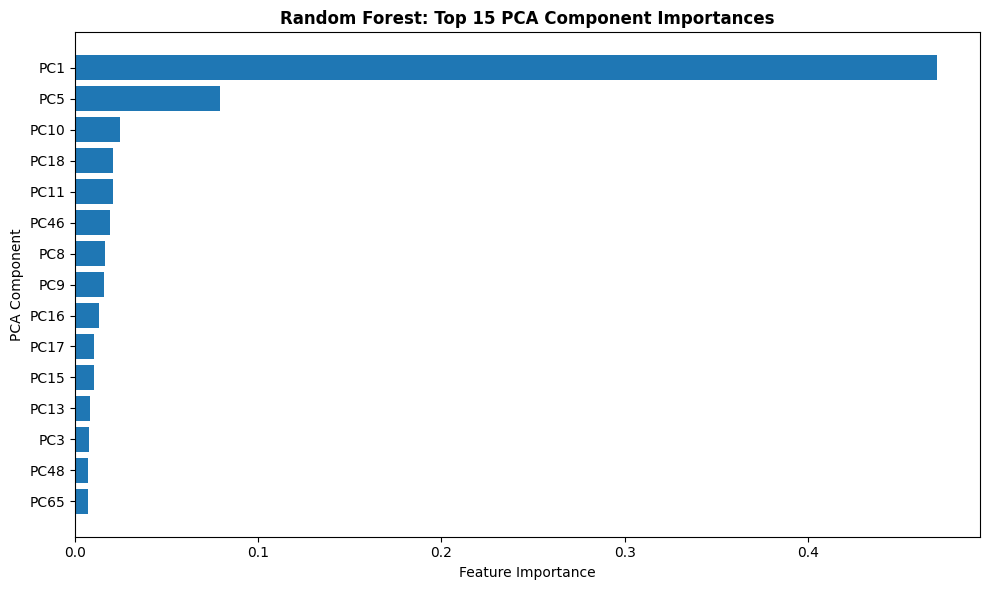

In [37]:

# ==========================================
# MODEL 6: RANDOM FOREST CLASSIFIER
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. TUNE n_estimators
# ==========================================

X_rf_train, X_rf_val, y_rf_train, y_rf_val = train_test_split(
    X_train_reduced,
    y_train_cls,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_cls
)

n_estimators_values = [50, 100, 150]
rf_tuning_results = []

for n in n_estimators_values:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_rf_train, y_rf_train)
    y_val_pred = model.predict(X_rf_val)

    rf_tuning_results.append({
        'n_estimators': n,
        'Validation Accuracy': accuracy_score(
            y_rf_val, y_val_pred
        ),
        'Weighted F1': f1_score(
            y_rf_val,
            y_val_pred,
            average='weighted',
            zero_division=0
        )
    })

rf_tuning_results = pd.DataFrame(rf_tuning_results)

rf_tuning_results = rf_tuning_results.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print("Random Forest: n_estimators Tuning Results")
display(rf_tuning_results)

best_n_estimators = int(
    rf_tuning_results.iloc[0]['n_estimators']
)

print(f"Best n_estimators: {best_n_estimators}")

# ==========================================
# 2. TRAIN FINAL RANDOM FOREST
# ==========================================

rf_cls = RandomForestClassifier(
    n_estimators=best_n_estimators,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_cls.fit(X_train_reduced, y_train_cls)

# ==========================================
# 3. PREDICTIONS AND EVALUATION
# ==========================================

y_pred_rf = rf_cls.predict(X_test_reduced)

rf_acc = accuracy_score(y_test_cls, y_pred_rf)

rf_prec = precision_score(
    y_test_cls,
    y_pred_rf,
    average='weighted',
    zero_division=0
)

rf_rec = recall_score(
    y_test_cls,
    y_pred_rf,
    average='weighted',
    zero_division=0
)

rf_f1 = f1_score(
    y_test_cls,
    y_pred_rf,
    average='weighted',
    zero_division=0
)

print("\nModel 6: Random Forest Classifier")
print(f"Best n_estimators: {best_n_estimators}")
print(f"Accuracy: {rf_acc:.4f}")
print(f"Precision: {rf_prec:.4f}")
print(f"Recall: {rf_rec:.4f}")
print(f"Weighted F1: {rf_f1:.4f}")

# ==========================================
# 4. FEATURE IMPORTANCE
# ==========================================

feature_importance_rf = pd.DataFrame({
    'Feature': [
        f'PC{i + 1}'
        for i in range(X_train_reduced.shape[1])
    ],
    'Importance': rf_cls.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\nTop 15 Important PCA Components")
display(feature_importance_rf.head(15))

# Plot top 15 components
top_features_rf = (
    feature_importance_rf.head(15)
    .sort_values(by='Importance', ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features_rf['Feature'],
    top_features_rf['Importance']
)

plt.title(
    'Random Forest: Top 15 PCA Component Importances',
    fontweight='bold'
)
plt.xlabel('Feature Importance')
plt.ylabel('PCA Component')

plt.tight_layout()
plt.show()


AdaBoost Hyperparameter Tuning Results


,n_estimators,learning_rate,Validation Accuracy,Weighted F1
0,150,0.5,0.935768,0.935887
1,100,0.5,0.935635,0.935790
2,50,0.5,0.933031,0.933299
3,150,0.1,0.932296,0.932509
4,50,1.0,0.931361,0.931921
5,50,0.1,0.931295,0.931282
6,100,1.0,0.931161,0.931657
7,100,0.1,0.930894,0.930562
8,150,1.0,0.930026,0.930416


Best n_estimators: 150
Best learning_rate: 0.5

Model 7: AdaBoost Classifier
Best n_estimators: 150
Best learning_rate: 0.5
Accuracy: 0.9337
Precision: 0.9337
Recall: 0.9337
Weighted F1: 0.9336


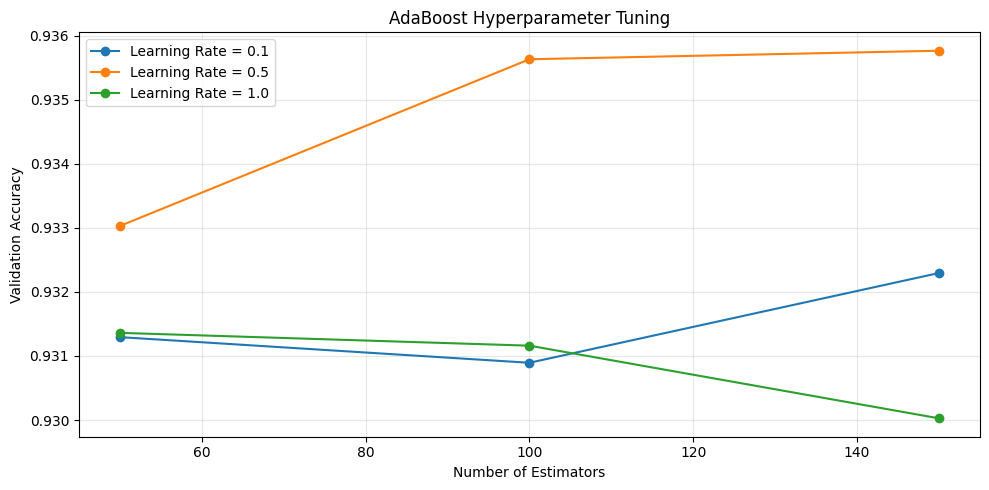

In [38]:

# ==========================================
# MODEL 7: ADABOOST CLASSIFIER
# ==========================================

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. HYPERPARAMETER TUNING
# ==========================================

n_estimators_values = [50, 100, 150]
learning_rate_values = [0.1, 0.5, 1.0]

# Use a validation split from training data
X_ada_train, X_ada_val, y_ada_train, y_ada_val = train_test_split(
    X_train_reduced,
    y_train_cls,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_cls
)

ada_tuning_results = []

for n in n_estimators_values:
    for rate in learning_rate_values:

        model = AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=1,
                random_state=RANDOM_STATE
            ),
            n_estimators=n,
            learning_rate=rate,
            random_state=RANDOM_STATE
        )

        model.fit(X_ada_train, y_ada_train)
        y_val_pred = model.predict(X_ada_val)

        ada_tuning_results.append({
            'n_estimators': n,
            'learning_rate': rate,
            'Validation Accuracy': accuracy_score(
                y_ada_val, y_val_pred
            ),
            'Weighted F1': f1_score(
                y_ada_val,
                y_val_pred,
                average='weighted',
                zero_division=0
            )
        })

ada_tuning_results = pd.DataFrame(ada_tuning_results)

ada_tuning_results = ada_tuning_results.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print("AdaBoost Hyperparameter Tuning Results")
display(ada_tuning_results)

best_n_estimators_ada = int(
    ada_tuning_results.iloc[0]['n_estimators']
)

best_learning_rate_ada = float(
    ada_tuning_results.iloc[0]['learning_rate']
)

print(f"Best n_estimators: {best_n_estimators_ada}")
print(f"Best learning_rate: {best_learning_rate_ada}")

# ==========================================
# 2. TRAIN FINAL ADABOOST MODEL
# ==========================================

ada_cls = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=RANDOM_STATE
    ),
    n_estimators=best_n_estimators_ada,
    learning_rate=best_learning_rate_ada,
    random_state=RANDOM_STATE
)

ada_cls.fit(X_train_reduced, y_train_cls)

# ==========================================
# 3. TEST SET EVALUATION
# ==========================================

y_pred_ada = ada_cls.predict(X_test_reduced)

ada_acc = accuracy_score(y_test_cls, y_pred_ada)

ada_prec = precision_score(
    y_test_cls,
    y_pred_ada,
    average='weighted',
    zero_division=0
)

ada_rec = recall_score(
    y_test_cls,
    y_pred_ada,
    average='weighted',
    zero_division=0
)

ada_f1 = f1_score(
    y_test_cls,
    y_pred_ada,
    average='weighted',
    zero_division=0
)

print("\nModel 7: AdaBoost Classifier")
print(f"Best n_estimators: {best_n_estimators_ada}")
print(f"Best learning_rate: {best_learning_rate_ada}")
print(f"Accuracy: {ada_acc:.4f}")
print(f"Precision: {ada_prec:.4f}")
print(f"Recall: {ada_rec:.4f}")
print(f"Weighted F1: {ada_f1:.4f}")

# ==========================================
# 4. VISUALIZE TUNING RESULTS
# ==========================================

plt.figure(figsize=(10, 5))

for rate in learning_rate_values:
    subset = ada_tuning_results[
        ada_tuning_results['learning_rate'] == rate
    ].sort_values('n_estimators')

    plt.plot(
        subset['n_estimators'],
        subset['Validation Accuracy'],
        marker='o',
        label=f'Learning Rate = {rate}'
    )

plt.title('AdaBoost Hyperparameter Tuning')
plt.xlabel('Number of Estimators')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Gradient Boosting Tuning Results


,n_estimators,learning_rate,Validation Accuracy,Weighted F1
0,100,0.2,0.952333,0.952428
1,50,0.2,0.946667,0.946770
2,100,0.1,0.946667,0.946821
3,50,0.1,0.943667,0.943863


Best n_estimators: 100
Best learning_rate: 0.2

Model 8: Gradient Boosting Classifier
Best n_estimators: 100
Best learning_rate: 0.2
Accuracy: 0.9551
Precision: 0.9551
Recall: 0.9551
Weighted F1: 0.9551


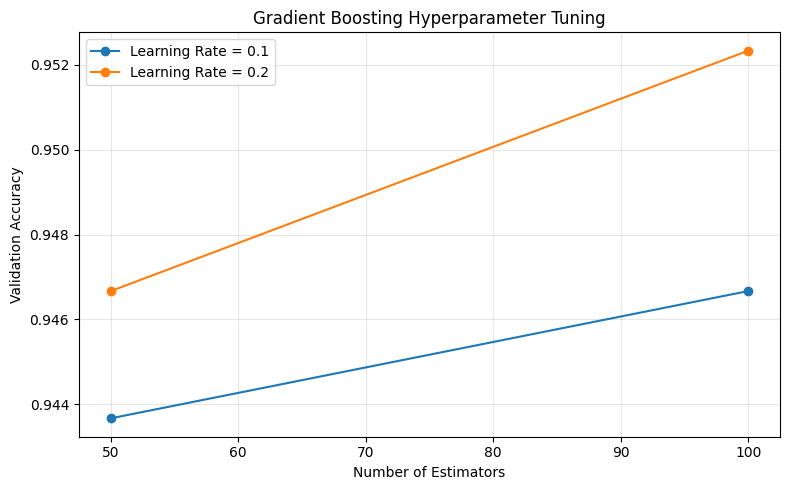

In [40]:

# ==========================================
# MODEL 8: GRADIENT BOOSTING CLASSIFIER
# FAST VERSION
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. CREATE A SMALL TUNING SAMPLE
# ==========================================

X_gb_sample, _, y_gb_sample, _ = train_test_split(
    X_train_reduced,
    y_train_cls,
    train_size=min(15000, len(y_train_cls)),
    random_state=RANDOM_STATE,
    stratify=y_train_cls
)

X_gb_train, X_gb_val, y_gb_train, y_gb_val = train_test_split(
    X_gb_sample,
    y_gb_sample,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_gb_sample
)

# ==========================================
# 2. HYPERPARAMETER TUNING
# ==========================================

n_estimators_values_gb = [50, 100]
learning_rate_values_gb = [0.1, 0.2]

gb_tuning_results = []

for n in n_estimators_values_gb:
    for rate in learning_rate_values_gb:

        model = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=rate,
            max_depth=2,
            random_state=RANDOM_STATE
        )

        model.fit(X_gb_train, y_gb_train)
        y_val_pred = model.predict(X_gb_val)

        gb_tuning_results.append({
            'n_estimators': n,
            'learning_rate': rate,
            'Validation Accuracy': accuracy_score(
                y_gb_val, y_val_pred
            ),
            'Weighted F1': f1_score(
                y_gb_val,
                y_val_pred,
                average='weighted',
                zero_division=0
            )
        })

gb_tuning_results = pd.DataFrame(gb_tuning_results)

gb_tuning_results = gb_tuning_results.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print("Gradient Boosting Tuning Results")
display(gb_tuning_results)

best_n_estimators_gb = int(
    gb_tuning_results.iloc[0]['n_estimators']
)
best_learning_rate_gb = float(
    gb_tuning_results.iloc[0]['learning_rate']
)

print(f"Best n_estimators: {best_n_estimators_gb}")
print(f"Best learning_rate: {best_learning_rate_gb}")

# ==========================================
# 3. TRAIN FINAL MODEL ON FULL TRAINING DATA
# ==========================================

gb_cls = GradientBoostingClassifier(
    n_estimators=best_n_estimators_gb,
    learning_rate=best_learning_rate_gb,
    max_depth=2,
    random_state=RANDOM_STATE
)

gb_cls.fit(X_train_reduced, y_train_cls)

# ==========================================
# 4. TEST SET EVALUATION
# ==========================================

y_pred_gb = gb_cls.predict(X_test_reduced)

gb_acc = accuracy_score(y_test_cls, y_pred_gb)
gb_prec = precision_score(
    y_test_cls, y_pred_gb,
    average='weighted', zero_division=0
)
gb_rec = recall_score(
    y_test_cls, y_pred_gb,
    average='weighted', zero_division=0
)
gb_f1 = f1_score(
    y_test_cls, y_pred_gb,
    average='weighted', zero_division=0
)

print("\nModel 8: Gradient Boosting Classifier")
print(f"Best n_estimators: {best_n_estimators_gb}")
print(f"Best learning_rate: {best_learning_rate_gb}")
print(f"Accuracy: {gb_acc:.4f}")
print(f"Precision: {gb_prec:.4f}")
print(f"Recall: {gb_rec:.4f}")
print(f"Weighted F1: {gb_f1:.4f}")

# ==========================================
# 5. PLOT TUNING RESULTS
# ==========================================

plt.figure(figsize=(8, 5))

for rate in learning_rate_values_gb:
    subset = gb_tuning_results[
        gb_tuning_results['learning_rate'] == rate
    ].sort_values('n_estimators')

    plt.plot(
        subset['n_estimators'],
        subset['Validation Accuracy'],
        marker='o',
        label=f'Learning Rate = {rate}'
    )

plt.title('Gradient Boosting Hyperparameter Tuning')
plt.xlabel('Number of Estimators')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Bagging Hyperparameter Tuning Results


,n_estimators,Validation Accuracy,Weighted F1
0,20,0.952667,0.952811
1,10,0.948333,0.948527
2,5,0.943667,0.943943


Best n_estimators: 20

Model 9: Bagging Classifier
Best n_estimators: 20
Accuracy: 0.9548
Precision: 0.9548
Recall: 0.9548
Weighted F1: 0.9548


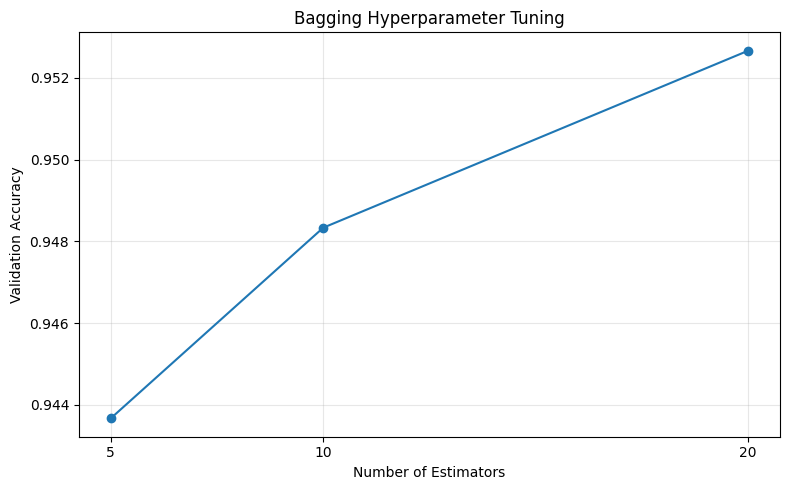

In [41]:

# ==========================================
# MODEL 9: BAGGING CLASSIFIER
# ==========================================

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. CREATE A SMALL TUNING SAMPLE
# ==========================================

X_bag_sample, _, y_bag_sample, _ = train_test_split(
    X_train_reduced,
    y_train_cls,
    train_size=min(15000, len(y_train_cls)),
    random_state=RANDOM_STATE,
    stratify=y_train_cls
)

X_bag_train, X_bag_val, y_bag_train, y_bag_val = train_test_split(
    X_bag_sample,
    y_bag_sample,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_bag_sample
)

# ==========================================
# 2. HYPERPARAMETER TUNING
# ==========================================

n_estimators_values_bag = [5, 10, 20]
bag_tuning_results = []

for n in n_estimators_values_bag:

    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=10,
            random_state=RANDOM_STATE
        ),
        n_estimators=n,
        max_samples=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_bag_train, y_bag_train)
    y_val_pred = model.predict(X_bag_val)

    bag_tuning_results.append({
        'n_estimators': n,
        'Validation Accuracy': accuracy_score(
            y_bag_val, y_val_pred
        ),
        'Weighted F1': f1_score(
            y_bag_val,
            y_val_pred,
            average='weighted',
            zero_division=0
        )
    })

bag_tuning_results = pd.DataFrame(bag_tuning_results)

bag_tuning_results = bag_tuning_results.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print("Bagging Hyperparameter Tuning Results")
display(bag_tuning_results)

best_n_estimators_bag = int(
    bag_tuning_results.iloc[0]['n_estimators']
)

print(f"Best n_estimators: {best_n_estimators_bag}")

# ==========================================
# 3. TRAIN FINAL MODEL ON FULL TRAINING DATA
# ==========================================

bag_cls = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=10,
        random_state=RANDOM_STATE
    ),
    n_estimators=best_n_estimators_bag,
    max_samples=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bag_cls.fit(X_train_reduced, y_train_cls)

# ==========================================
# 4. TEST SET EVALUATION
# ==========================================

y_pred_bag = bag_cls.predict(X_test_reduced)

bag_acc = accuracy_score(y_test_cls, y_pred_bag)

bag_prec = precision_score(
    y_test_cls,
    y_pred_bag,
    average='weighted',
    zero_division=0
)

bag_rec = recall_score(
    y_test_cls,
    y_pred_bag,
    average='weighted',
    zero_division=0
)

bag_f1 = f1_score(
    y_test_cls,
    y_pred_bag,
    average='weighted',
    zero_division=0
)

print("\nModel 9: Bagging Classifier")
print(f"Best n_estimators: {best_n_estimators_bag}")
print(f"Accuracy: {bag_acc:.4f}")
print(f"Precision: {bag_prec:.4f}")
print(f"Recall: {bag_rec:.4f}")
print(f"Weighted F1: {bag_f1:.4f}")

# ==========================================
# 5. PLOT TUNING RESULTS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    bag_tuning_results['n_estimators'],
    bag_tuning_results['Validation Accuracy'],
    marker='o'
)

plt.title('Bagging Hyperparameter Tuning')
plt.xlabel('Number of Estimators')
plt.ylabel('Validation Accuracy')
plt.xticks(n_estimators_values_bag)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


MLP Hyperparameter Tuning Results


,Hidden Layers,Activation,Validation Accuracy,Weighted F1
0,"(100,)",relu,0.950667,0.950815
1,"(64, 32)",tanh,0.950000,0.950039
2,"(64,)",tanh,0.949667,0.949823
3,"(64, 32)",relu,0.946667,0.946692
4,"(64,)",relu,0.945000,0.945187
5,"(100,)",tanh,0.944333,0.944533


Best hidden layers: (100,)
Best activation: relu

Model 10: MLP Classifier
Best hidden layers: (100,)
Best activation: relu
Accuracy: 0.9564
Precision: 0.9563
Recall: 0.9564
Weighted F1: 0.9563


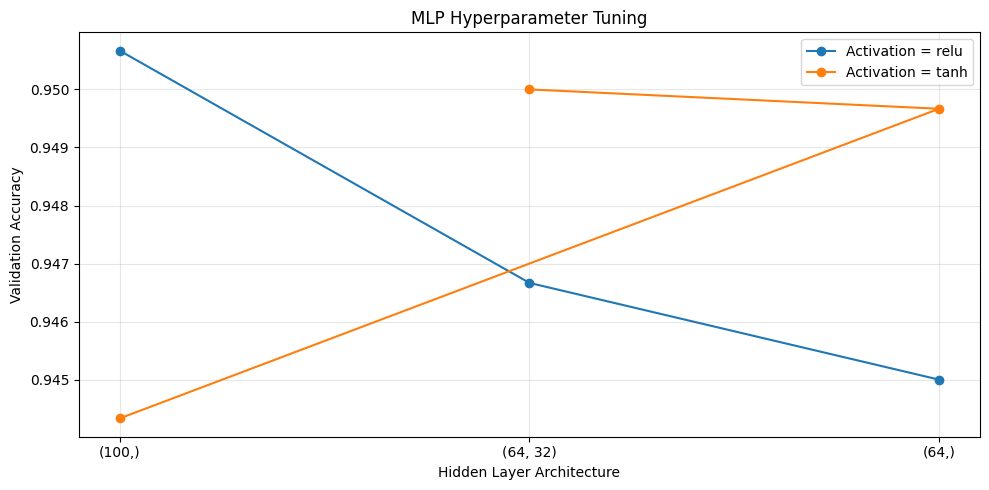

In [42]:

# ==========================================
# MODEL 10: MLP CLASSIFIER
# ==========================================

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. CREATE A SMALL TUNING SAMPLE
# ==========================================

X_mlp_sample, _, y_mlp_sample, _ = train_test_split(
    X_train_reduced,
    y_train_cls,
    train_size=min(15000, len(y_train_cls)),
    random_state=RANDOM_STATE,
    stratify=y_train_cls
)

X_mlp_train, X_mlp_val, y_mlp_train, y_mlp_val = train_test_split(
    X_mlp_sample,
    y_mlp_sample,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mlp_sample
)

# ==========================================
# 2. HYPERPARAMETER TUNING
# ==========================================

hidden_layer_options = [(64,), (100,), (64, 32)]
activation_options = ['relu', 'tanh']

mlp_tuning_results = []

for hidden_layers in hidden_layer_options:
    for activation in activation_options:

        model = MLPClassifier(
            hidden_layer_sizes=hidden_layers,
            activation=activation,
            solver='adam',
            alpha=0.0001,
            max_iter=100,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=5,
            random_state=RANDOM_STATE
        )

        model.fit(X_mlp_train, y_mlp_train)
        y_val_pred = model.predict(X_mlp_val)

        mlp_tuning_results.append({
            'Hidden Layers': str(hidden_layers),
            'Activation': activation,
            'Validation Accuracy': accuracy_score(
                y_mlp_val, y_val_pred
            ),
            'Weighted F1': f1_score(
                y_mlp_val,
                y_val_pred,
                average='weighted',
                zero_division=0
            )
        })

mlp_tuning_results = pd.DataFrame(mlp_tuning_results)

mlp_tuning_results = mlp_tuning_results.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print("MLP Hyperparameter Tuning Results")
display(mlp_tuning_results)

best_hidden_layers = eval(
    mlp_tuning_results.iloc[0]['Hidden Layers']
)
best_activation = mlp_tuning_results.iloc[0]['Activation']

print(f"Best hidden layers: {best_hidden_layers}")
print(f"Best activation: {best_activation}")

# ==========================================
# 3. TRAIN FINAL MLP MODEL
# ==========================================

mlp_cls = MLPClassifier(
    hidden_layer_sizes=best_hidden_layers,
    activation=best_activation,
    solver='adam',
    alpha=0.0001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=RANDOM_STATE
)

mlp_cls.fit(X_train_reduced, y_train_cls)

# ==========================================
# 4. TEST SET EVALUATION
# ==========================================

y_pred_mlp = mlp_cls.predict(X_test_reduced)

mlp_acc = accuracy_score(y_test_cls, y_pred_mlp)

mlp_prec = precision_score(
    y_test_cls,
    y_pred_mlp,
    average='weighted',
    zero_division=0
)

mlp_rec = recall_score(
    y_test_cls,
    y_pred_mlp,
    average='weighted',
    zero_division=0
)

mlp_f1 = f1_score(
    y_test_cls,
    y_pred_mlp,
    average='weighted',
    zero_division=0
)

print("\nModel 10: MLP Classifier")
print(f"Best hidden layers: {best_hidden_layers}")
print(f"Best activation: {best_activation}")
print(f"Accuracy: {mlp_acc:.4f}")
print(f"Precision: {mlp_prec:.4f}")
print(f"Recall: {mlp_rec:.4f}")
print(f"Weighted F1: {mlp_f1:.4f}")

# ==========================================
# 5. VISUALIZE TUNING RESULTS
# ==========================================

plt.figure(figsize=(10, 5))

for activation in activation_options:
    subset = mlp_tuning_results[
        mlp_tuning_results['Activation'] == activation
    ]

    plt.plot(
        subset['Hidden Layers'],
        subset['Validation Accuracy'],
        marker='o',
        label=f'Activation = {activation}'
    )

plt.title('MLP Hyperparameter Tuning')
plt.xlabel('Hidden Layer Architecture')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [43]:

# ==========================================
# PART B: COMPARISON OF MODELS 6-10
# ==========================================

from sklearn.metrics import roc_auc_score
import pandas as pd

# ==========================================
# 1. CALCULATE MULTICLASS ROC-AUC (OvR)
# ==========================================

# Use the same class order for every model
class_order = ['Low', 'Medium', 'High']

y_test_bin = pd.get_dummies(
    pd.Categorical(y_test_cls, categories=class_order)
).to_numpy()

models_part_b = {
    'Random Forest': rf_cls,
    'AdaBoost': ada_cls,
    'Gradient Boosting': gb_cls,
    'Bagging': bag_cls,
    'MLP': mlp_cls
}

predictions_part_b = {
    'Random Forest': y_pred_rf,
    'AdaBoost': y_pred_ada,
    'Gradient Boosting': y_pred_gb,
    'Bagging': y_pred_bag,
    'MLP': y_pred_mlp
}

metrics_part_b = {
    'Random Forest': [rf_acc, rf_prec, rf_rec, rf_f1],
    'AdaBoost': [ada_acc, ada_prec, ada_rec, ada_f1],
    'Gradient Boosting': [gb_acc, gb_prec, gb_rec, gb_f1],
    'Bagging': [bag_acc, bag_prec, bag_rec, bag_f1],
    'MLP': [mlp_acc, mlp_prec, mlp_rec, mlp_f1]
}

# ==========================================
# 2. BUILD COMPARISON TABLE
# ==========================================

comparison_part_b = []

for name, model in models_part_b.items():

    # Reorder probability columns to Low, Medium, High
    model_classes = list(model.classes_)
    probabilities = model.predict_proba(X_test_reduced)

    column_order = [
        model_classes.index(label)
        for label in class_order
    ]

    probabilities = probabilities[:, column_order]

    roc_auc = roc_auc_score(
        y_test_bin,
        probabilities,
        multi_class='ovr',
        average='weighted'
    )

    acc, prec, rec, f1 = metrics_part_b[name]

    comparison_part_b.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'Weighted F1': f1,
        'ROC-AUC (OvR)': roc_auc
    })

comparison_part_b = pd.DataFrame(comparison_part_b)

comparison_part_b = comparison_part_b.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("PART B: CLASSIFIER COMPARISON (MODELS 6-10)")
display(
    comparison_part_b.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'Weighted F1': '{:.4f}',
        'ROC-AUC (OvR)': '{:.4f}'
    })
)

# ==========================================
# 3. IDENTIFY BEST MODEL
# ==========================================

best_model_part_b = comparison_part_b.iloc[0]

print("\nBest Part B Model (by Accuracy):")
print(f"Model: {best_model_part_b['Model']}")
print(f"Accuracy: {best_model_part_b['Accuracy']:.4f}")
print(f"Weighted F1: {best_model_part_b['Weighted F1']:.4f}")
print(f"ROC-AUC (OvR): {best_model_part_b['ROC-AUC (OvR)']:.4f}")


PART B: CLASSIFIER COMPARISON (MODELS 6-10)


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC (OvR)
0,MLP,0.9564,0.9563,0.9564,0.9563,0.9949
1,Gradient Boosting,0.9551,0.9551,0.9551,0.9551,0.9945
2,Bagging,0.9548,0.9548,0.9548,0.9548,0.9937
3,Random Forest,0.9422,0.9424,0.9422,0.9423,0.9908
4,AdaBoost,0.9337,0.9337,0.9337,0.9336,0.9894



Best Part B Model (by Accuracy):
Model: MLP
Accuracy: 0.9564
Weighted F1: 0.9563
ROC-AUC (OvR): 0.9949


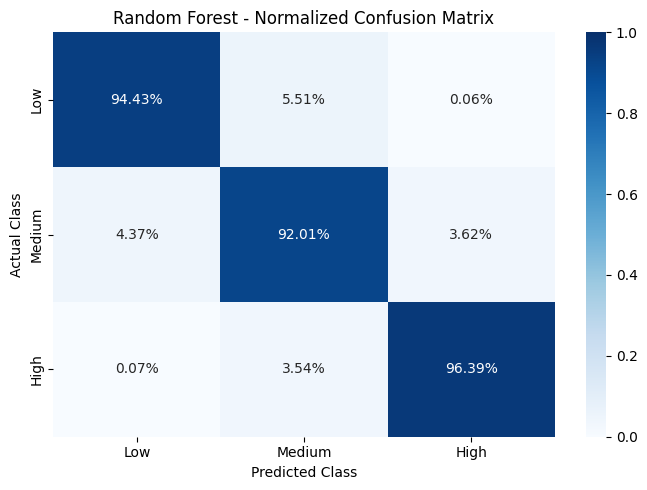

In [45]:

# ==========================================
# MODEL 6: RANDOM FOREST CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = ['Low', 'Medium', 'High']

cm_rf = confusion_matrix(
    y_test_cls,
    y_pred_rf,
    labels=class_labels,
    normalize='true'
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1
)

plt.title('Random Forest - Normalized Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


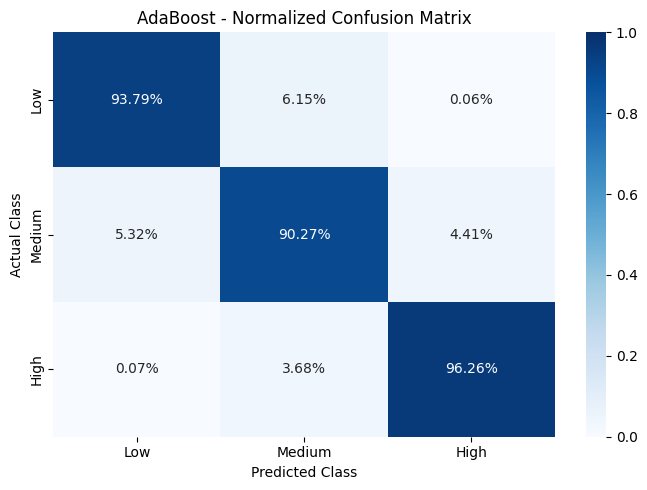

In [46]:

# ==========================================
# MODEL 7: ADABOOST CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = ['Low', 'Medium', 'High']

cm_ada = confusion_matrix(
    y_test_cls,
    y_pred_ada,
    labels=class_labels,
    normalize='true'
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_ada,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1
)

plt.title('AdaBoost - Normalized Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


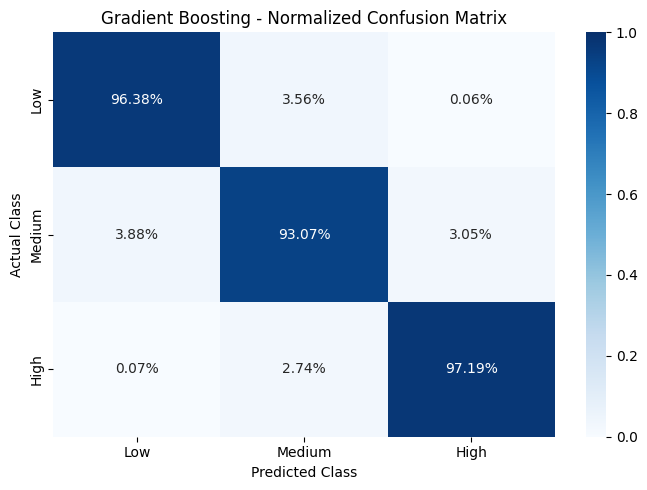

In [47]:

# ==========================================
# MODEL 8: GRADIENT BOOSTING CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = ['Low', 'Medium', 'High']

cm_gb = confusion_matrix(
    y_test_cls,
    y_pred_gb,
    labels=class_labels,
    normalize='true'
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1
)

plt.title('Gradient Boosting - Normalized Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


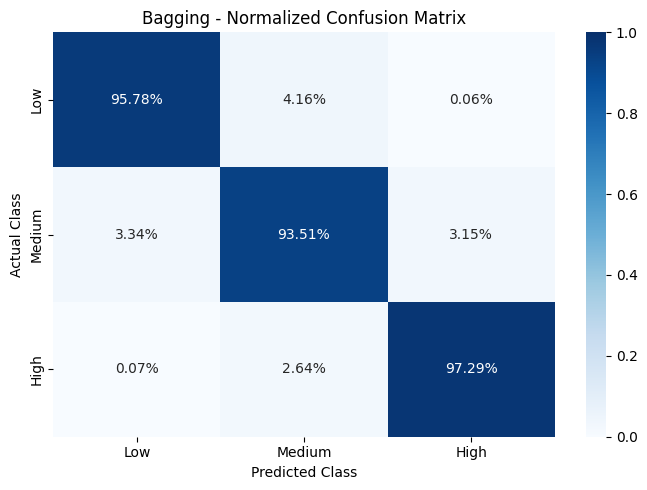

In [48]:

# ==========================================
# MODEL 9: BAGGING CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = ['Low', 'Medium', 'High']

cm_bag = confusion_matrix(
    y_test_cls,
    y_pred_bag,
    labels=class_labels,
    normalize='true'
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_bag,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1
)

plt.title('Bagging - Normalized Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


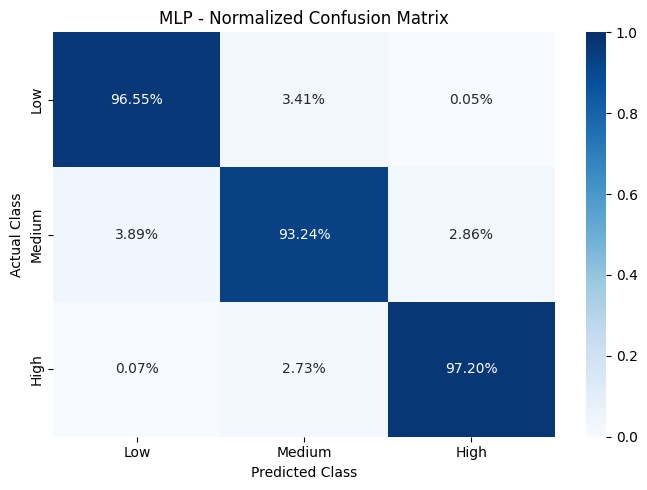

In [49]:

# ==========================================
# MODEL 10: MLP CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = ['Low', 'Medium', 'High']

cm_mlp = confusion_matrix(
    y_test_cls,
    y_pred_mlp,
    labels=class_labels,
    normalize='true'
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_mlp,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1
)

plt.title('MLP - Normalized Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


,Model,Accuracy,Precision,Recall,Weighted F1
0,Random Forest,0.9422,0.9424,0.9422,0.9423
1,AdaBoost,0.9337,0.9337,0.9337,0.9336
2,Gradient Boosting,0.9551,0.9551,0.9551,0.9551
3,Bagging,0.9548,0.9548,0.9548,0.9548
4,MLP,0.9564,0.9563,0.9564,0.9563


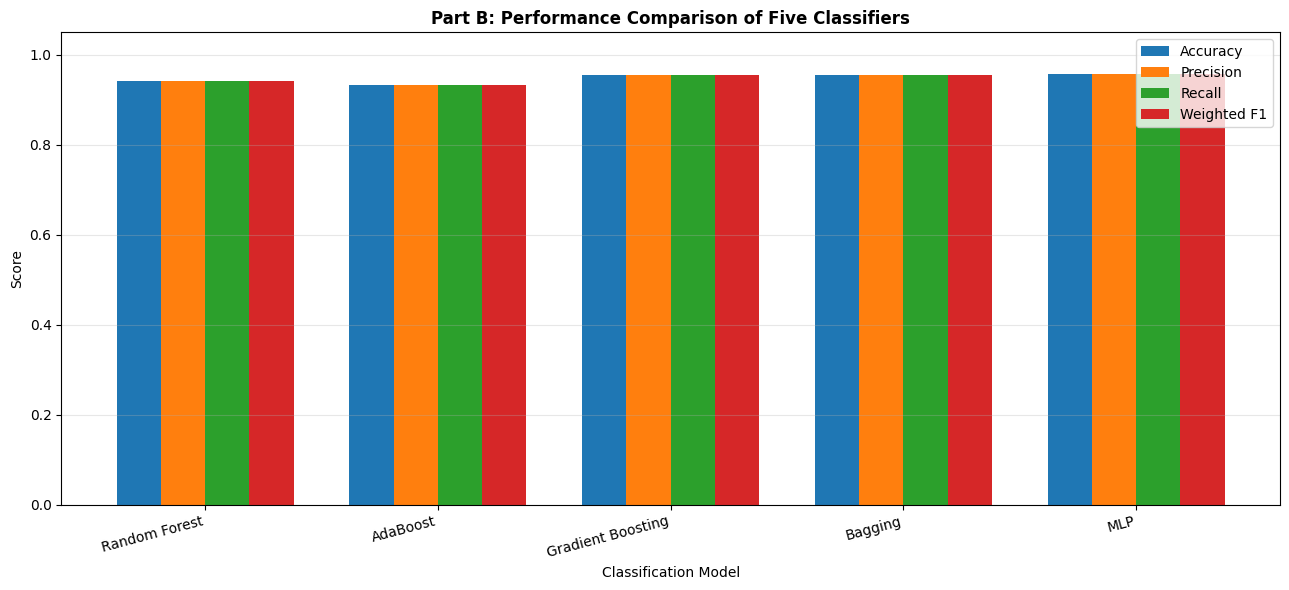

In [50]:

# ==========================================
# PART B: BAR PLOT COMPARISON (MODELS 6-10)
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

comparison_data_part_b = pd.DataFrame({
    'Model': [
        'Random Forest',
        'AdaBoost',
        'Gradient Boosting',
        'Bagging',
        'MLP'
    ],
    'Accuracy': [rf_acc, ada_acc, gb_acc, bag_acc, mlp_acc],
    'Precision': [rf_prec, ada_prec, gb_prec, bag_prec, mlp_prec],
    'Recall': [rf_rec, ada_rec, gb_rec, bag_rec, mlp_rec],
    'Weighted F1': [rf_f1, ada_f1, gb_f1, bag_f1, mlp_f1]
})

# Display the comparison table
display(
    comparison_data_part_b.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'Weighted F1': '{:.4f}'
    })
)

# ==========================================
# GROUPED BAR PLOT
# ==========================================

metrics = ['Accuracy', 'Precision', 'Recall', 'Weighted F1']
x = np.arange(len(comparison_data_part_b))
bar_width = 0.19

plt.figure(figsize=(13, 6))

for i, metric in enumerate(metrics):
    values = comparison_data_part_b[metric].values

    plt.bar(
        x + (i - 1.5) * bar_width,
        values,
        width=bar_width,
        label=metric
    )

plt.xticks(
    x,
    comparison_data_part_b['Model'],
    rotation=15,
    ha='right'
)

plt.ylim(0, 1.05)
plt.ylabel('Score')
plt.xlabel('Classification Model')
plt.title(
    'Part B: Performance Comparison of Five Classifiers',
    fontweight='bold'
)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [52]:

# ==========================================
# PART B: ROC-AUC FOR ALL FIVE CLASSIFIERS
# ==========================================

from sklearn.metrics import roc_auc_score
import pandas as pd

class_order = ['Low', 'Medium', 'High']

# One-hot encode actual labels in a fixed class order
y_test_bin = pd.get_dummies(
    pd.Categorical(y_test_cls, categories=class_order)
).to_numpy()

models_part_b = {
    'Random Forest': rf_cls,
    'AdaBoost': ada_cls,
    'Gradient Boosting': gb_cls,
    'Bagging': bag_cls,
    'MLP': mlp_cls
}

roc_auc_results_b = []

for name, model in models_part_b.items():

    # Predicted probabilities
    probabilities = model.predict_proba(X_test_reduced)

    # Ensure probability columns follow Low, Medium, High
    model_classes = list(model.classes_)
    column_order = [
        model_classes.index(label)
        for label in class_order
    ]
    probabilities = probabilities[:, column_order]

    auc = roc_auc_score(
        y_test_bin,
        probabilities,
        multi_class='ovr',
        average='weighted'
    )

    roc_auc_results_b.append({
        'Model': name,
        'ROC-AUC (OvR)': auc
    })

roc_auc_part_b = pd.DataFrame(roc_auc_results_b)

display(
    roc_auc_part_b.style.format({
        'ROC-AUC (OvR)': '{:.4f}'
    })
)


,Model,ROC-AUC (OvR)
0,Random Forest,0.9908
1,AdaBoost,0.9894
2,Gradient Boosting,0.9945
3,Bagging,0.9937
4,MLP,0.9949


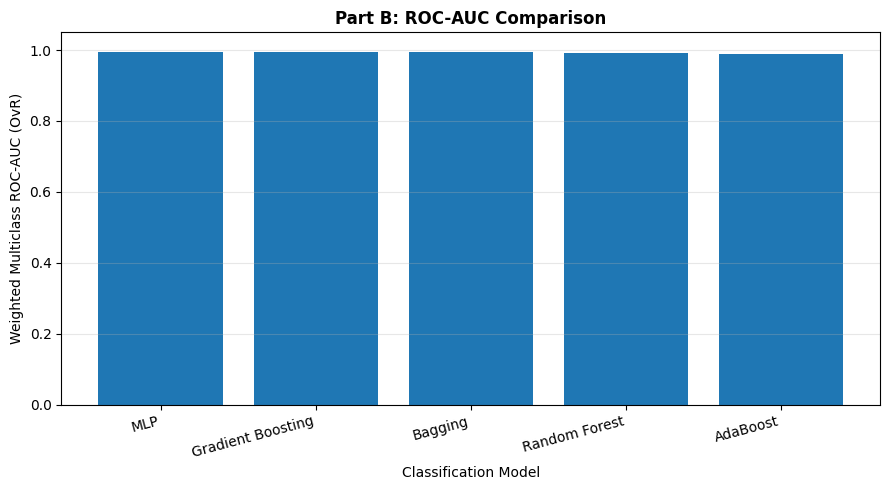

In [51]:

# ==========================================
# PART B: ROC-AUC COMPARISON
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_part_b['Model'],
    comparison_part_b['ROC-AUC (OvR)']
)

plt.ylim(0, 1.05)
plt.ylabel('Weighted Multiclass ROC-AUC (OvR)')
plt.xlabel('Classification Model')
plt.title('Part B: ROC-AUC Comparison', fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
